# Verbesserte Modelle: Financial Inclusion in Africa

**Ziel:** Die Baseline (Logistic Regression, CV-F1 ca. 0,49, Test-F1 ca. 0,51) mit Feature Engineering, Tuning und einem zweiten Algorithmus verbessern, das beste Modell bestimmen, es einmalig auf dem Test-Set bewerten und seine Fehler analysieren.

**Hauptmetrik:** F1-Score der Klasse "Bankkonto" (ergänzend Precision, Recall, PR-AUC).

**Modelle:**
- Modell 1: Logistic Regression mit Feature Engineering aus der EDA und Tuning
- Modell 2: Gradient Boosting (HistGradientBoosting) mit Tuning
- Referenz: Baseline-Modelle (Logistic Regression, Random Forest)

**Vorgehen:** Gleicher Split wie in der Baseline (Seed 42). Tuning per Cross-Validation nur auf dem Trainingsteil. Der Schwellenwert wird auf Out-of-Fold-Vorhersagen des Trainingsteils bestimmt. Das Test-Set wird nur für das beste Modell benutzt.

**Inhalt**
1. Setup
2. Daten und Split
3. Feature Engineering
4. Pipelines
5. Modell 1: Tuning
6. Modell 2: Tuning
7. Vergleich per Cross-Validation
8. Schwellenwert
9. Bestes Modell auf dem Test-Set
10. Fehleranalyse
11. Ergebnisübersicht und Fazit

## 1. Setup

**Ziel:** Bibliotheken laden und zentrale Einstellungen festlegen.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, GridSearchCV, RandomizedSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (make_scorer, f1_score, precision_score, recall_score,
                             roc_auc_score, average_precision_score, accuracy_score,
                             classification_report, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42
DATA_PATH = "../data/raw/Train.csv"

## 2. Daten und Split

**Ziel:** Exakt denselben Split wie in der Baseline verwenden, damit die Ergebnisse vergleichbar bleiben.

**Vorgehen:** `uniqueid` und `year` werden entfernt (das Jahr ist durch das Land vollständig bestimmt). Split 80/20, stratifiziert, gemischt, Seed 42. Die Prüfung am Ende stellt sicher, dass das Test-Set identisch zur Baseline ist (4.705 Personen, davon 662 mit Konto).

In [2]:
df = pd.read_csv(DATA_PATH)
y = (df["bank_account"] == "Yes").astype(int)
X = df.drop(columns=["bank_account", "uniqueid", "year"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, shuffle=True, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Anteil Klasse 1: Train {y_train.mean():.3f} | Test {y_test.mean():.3f}")
assert X_test.shape[0] == 4705 and y_test.sum() == 662, "Split weicht von der Baseline ab!"

Train: (18819, 10) | Test: (4705, 10)
Anteil Klasse 1: Train 0.141 | Test 0.141


**Fazit:** Der Split ist identisch zur Baseline (Train 18.819, Test 4.705 Zeilen, in beiden Teilen ca. 14,1 % Klasse 1). Damit sind die Werte der Baseline und der neuen Modelle direkt vergleichbar.

## 3. Feature Engineering

**Ziel:** Die Erkenntnisse aus der EDA als neue Merkmale nutzbar machen, vor allem für die Logistic Regression, die Interaktionen nicht selbst erkennt.

**Neue Merkmale:**
- `age_group`: Altersgruppen, falls das Alter nichtlinear wirkt (im Random Forest war es auffällig wichtig)
- `edu_country`: Bildung × Land (der Bildungseffekt unterscheidet sich je nach Land)
- `phone_edu`: Handyzugang × Bildung (Bildung wirkt fast nur mit Handyzugang)
- `loc_country`: Stadt/Land × Land (in Tansania war das Muster umgekehrt)
- `phone_secondary_plus`: Handyzugang und mindestens Sekundarbildung

Die Funktion arbeitet zeilenweise ohne gelernte Werte, es entsteht also kein Data Leakage. Sie wird später als Schritt in die Pipeline eingebaut.

In [3]:
NUM_COLS = ["household_size", "age_of_respondent"]
BASE_CAT = ["country", "location_type", "cellphone_access", "gender_of_respondent",
            "relationship_with_head", "marital_status", "education_level", "job_type"]
NEW_CAT = ["age_group", "edu_country", "phone_edu", "loc_country", "phone_secondary_plus"]
ALL_CAT = BASE_CAT + NEW_CAT

AGE_BINS = [0, 25, 35, 45, 55, 65, 120]
AGE_LABELS = ["<=25", "26-35", "36-45", "46-55", "56-65", "66+"]
HIGH_EDU = ["Secondary education", "Tertiary education", "Vocational/Specialised training"]


def add_features(data):
    data = data.copy()
    data["age_group"] = pd.cut(data["age_of_respondent"], bins=AGE_BINS,
                               labels=AGE_LABELS).astype(str)
    data["edu_country"] = data["education_level"] + " | " + data["country"]
    data["phone_edu"] = data["cellphone_access"] + " | " + data["education_level"]
    data["loc_country"] = data["location_type"] + " | " + data["country"]
    data["phone_secondary_plus"] = np.where(
        (data["cellphone_access"] == "Yes") & (data["education_level"].isin(HIGH_EDU)),
        "Yes", "No")
    return data


# Kontrolle
X_fe = add_features(X_train)
print(X_fe[NEW_CAT].nunique())
X_fe[NEW_CAT].head()

age_group                6
edu_country             24
phone_edu               12
loc_country              8
phone_secondary_plus     2
dtype: int64


,age_group,edu_country,phone_edu,loc_country,phone_secondary_plus
3535,26-35,Primary education | Kenya,Yes | Primary education,Rural | Kenya,No
10836,56-65,No formal education | Rwanda,No | No formal education,Rural | Rwanda,No
23078,26-35,Secondary education | Uganda,Yes | Secondary education,Rural | Uganda,Yes
10569,56-65,Primary education | Rwanda,No | Primary education,Rural | Rwanda,No
9135,26-35,Primary education | Rwanda,Yes | Primary education,Rural | Rwanda,No


**Fazit:** Es entstehen 5 neue kategoriale Merkmale (Altersgruppen: 6, Bildung × Land: [Anzahl], Handyzugang × Bildung: [Anzahl], Stadt/Land × Land: 8, Flag: 2). Seltene Kombinationen werden im One-Hot-Encoding über `min_frequency` automatisch zu einer Sammelkategorie zusammengefasst.

## 4. Pipelines

**Ziel:** Feature Engineering, Preprocessing und Modell in einer Pipeline kapseln. So werden in der Cross-Validation alle Schritte pro Fold neu gelernt und es entsteht kein Data Leakage.

**Aufbau:** `FunctionTransformer(add_features)` → `ColumnTransformer` (Standardisierung der numerischen Merkmale, One-Hot-Encoding der kategorialen) → Modell.

Beide Modelle nutzen `class_weight="balanced"` wie in der Baseline. Das Gradient Boosting bekommt dichtes One-Hot-Encoding und keine Skalierung.

In [5]:
def make_prep(cat_cols, scale=True, sparse=True, min_freq=50):
    return ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist",
                              min_frequency=min_freq, sparse_output=sparse), cat_cols),
    ])


def lr_pipe():
    return Pipeline([
        ("fe", FunctionTransformer(add_features)),
        ("prep", make_prep(ALL_CAT)),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=2000,
                                   random_state=RANDOM_STATE)),
    ])


def hgb_pipe():
    return Pipeline([
        ("fe", FunctionTransformer(add_features)),
        ("prep", make_prep(ALL_CAT, scale=False, sparse=False)),
        ("clf", HistGradientBoostingClassifier(class_weight="balanced",
                                               random_state=RANDOM_STATE)),
    ])


def baseline_pipe(model, scale=True):
    """Baseline wie im ersten Notebook (ohne neue Merkmale, ohne Tuning)."""
    prep = ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist",
                              min_frequency=100), BASE_CAT),
    ])
    return Pipeline([("prep", prep), ("clf", model)])

## 5. Modell 1: Logistic Regression mit Feature Engineering und Tuning

**Ziel:** Die besten Hyperparameter per Grid Search mit 5-facher stratifizierter Cross-Validation finden (nur auf dem Trainingsteil, Zielmetrik F1).

**Gesucht wird:**
- `C`: Stärke der Regularisierung (kleiner = stärker). Bei vielen Interaktionsmerkmalen verhindert sie Überanpassung.
- `min_frequency`: ab wie vielen Fällen eine Kategorie ein eigenes Merkmal bekommt.

Zusätzlich wird der F1 auf den Trainingsfolds ausgewiesen, um Overfitting zu erkennen.

In [6]:
cv_tune = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_lr = GridSearchCV(
    lr_pipe(),
    param_grid={"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
                "prep__cat__min_frequency": [20, 50, 100]},
    scoring="f1", cv=cv_tune, n_jobs=-1, return_train_score=True)
grid_lr.fit(X_train, y_train)

res_lr = pd.DataFrame(grid_lr.cv_results_).sort_values("rank_test_score")
display(res_lr[["param_clf__C", "param_prep__cat__min_frequency",
                "mean_test_score", "std_test_score", "mean_train_score"]].head(8).round(3))
print("Beste Parameter:", grid_lr.best_params_)
print(f"Bester CV-F1: {grid_lr.best_score_:.3f}")

,param_clf__C,param_prep__cat__min_frequency,mean_test_score,std_test_score,mean_train_score
19,10.00,50,0.496,0.011,0.501
14,1.00,100,0.496,0.010,0.501
18,10.00,20,0.496,0.011,0.501
11,0.30,100,0.495,0.010,0.501
1,0.01,50,0.495,0.009,0.497
12,1.00,20,0.495,0.011,0.501
15,3.00,20,0.495,0.010,0.501
2,0.01,100,0.495,0.009,0.498


Beste Parameter: {'clf__C': 10, 'prep__cat__min_frequency': 50}
Bester CV-F1: 0.496


**Fazit:**
- **Beste Parameter:** C = 10 und min_frequency = 50 mit CV-F1 = 0,496 ± 0,011. Die Baseline lag auf denselben Folds bei 0,492 ± 0,007. Das Plus von **0,004** ist deutlich kleiner als die Streuung über die Folds (ca. 0,01) und damit **kein belastbarer Gewinn**. Weil das beste von 21 Parametersätzen gewählt wurde, ist der Wert zudem leicht optimistisch.
- **Effekt der neuen Merkmale allein:** Bei den Einstellungen der Baseline (C = 1, min_frequency = 100) erreicht das Modell mit Interaktionen und Altersgruppen 0,496, die Baseline ohne sie 0,492. Auch hier sind es nur +0,004.
- **Hyperparameter spielen kaum eine Rolle:** Die acht besten Kombinationen liegen zwischen 0,495 und 0,496, selbst die stärkste Regularisierung (C = 0,01) erreicht 0,495. Die Unterschiede sind etwa zehnmal kleiner als die Streuung. Dass das beste C mit 10 am Rand des Suchbereichs liegt, ist unkritisch, denn die Werte sind flach und ein größerer Bereich würde nichts ändern.
- **Kein Overfitting:** Train-F1 (0,501) und CV-F1 (0,496) liegen nur 0,005 auseinander, obwohl die Interaktionsmerkmale viele zusätzliche Spalten erzeugen.
- **Einordnung:** Die Interaktionen und Altersgruppen aus der EDA verbessern die Logistic Regression nicht messbar. Eine mögliche Erklärung (Hypothese): Die Haupteffekte (Bildung, Beruf, Handyzugang, Land) tragen bereits fast die gesamte nutzbare Information. Die Interaktionen kommen darüber nur schwach hinzu, und der F1 stößt mit diesen Merkmalen bei ca. 0,5 an eine Grenze.
- **Konsequenz:** Das Modell bleibt als erklärbares Modell 1 im Vergleich. Ob ein nichtlineares Modell mehr herausholt, prüfen wir in Abschnitt 6.

## 6. Modell 2: Gradient Boosting mit Tuning

**Ziel:** Hyperparameter des Gradient Boosting per Random Search (30 zufällige Kombinationen) mit derselben Cross-Validation und Zielmetrik finden.

**Motivation:** Feature Engineering und Tuning haben die Logistic Regression kaum verbessert (CV-F1 0,496 gegenüber 0,492). Deshalb prüfen wir, ob ein nichtlineares Modell, das Interaktionen selbst findet, mehr Information aus denselben Merkmalen holt, oder ob die Grenze bei den Daten liegt und nicht beim Modelltyp.

**Gesucht wird:** Lernrate, Baumtiefe und Blattzahl, Mindestgröße der Blätter, L2-Regularisierung und Anzahl der Iterationen. Kleine Bäume und starke Regularisierung begrenzen die Überanpassung, die beim Random Forest der Baseline sichtbar war.

**Hinweis:** Dieser Schritt dauert einige Minuten. Mit `n_iter` lässt sich die Zahl der Versuche anpassen.

In [7]:
param_dist = {
    "clf__learning_rate": [0.03, 0.05, 0.1],
    "clf__max_depth": [3, 4, 6, None],
    "clf__max_leaf_nodes": [8, 15, 31],
    "clf__min_samples_leaf": [20, 50, 100, 200],
    "clf__l2_regularization": [0, 0.1, 1, 10],
    "clf__max_iter": [100, 200, 400],
}

rs_hgb = RandomizedSearchCV(
    hgb_pipe(), param_distributions=param_dist, n_iter=30,
    scoring="f1", cv=cv_tune, n_jobs=-1, random_state=RANDOM_STATE,
    return_train_score=True)
rs_hgb.fit(X_train, y_train)

res_hgb = pd.DataFrame(rs_hgb.cv_results_).sort_values("rank_test_score")
cols = ["param_clf__learning_rate", "param_clf__max_depth", "param_clf__max_leaf_nodes",
        "param_clf__min_samples_leaf", "param_clf__l2_regularization",
        "param_clf__max_iter", "mean_test_score", "std_test_score", "mean_train_score"]
display(res_hgb[cols].head(8).round(3))
print("Beste Parameter:", rs_hgb.best_params_)
print(f"Bester CV-F1: {rs_hgb.best_score_:.3f}")

,param_clf__learning_rate,param_clf__max_depth,param_clf__max_leaf_nodes,param_clf__min_samples_leaf,param_clf__l2_regularization,param_clf__max_iter,mean_test_score,std_test_score,mean_train_score
21,0.10,6,31,200,0.0,100,0.504,0.009,0.521
9,0.10,4,31,20,0.1,100,0.503,0.013,0.522
2,0.05,4,15,20,0.1,200,0.503,0.009,0.517
27,0.10,3,31,50,0.0,100,0.502,0.015,0.512
15,0.10,3,31,100,0.0,100,0.502,0.011,0.513
28,0.10,4,15,50,1.0,100,0.501,0.011,0.518
22,0.03,4,31,20,10.0,100,0.501,0.018,0.511
20,0.03,None,31,20,0.1,100,0.501,0.013,0.530


Beste Parameter: {'clf__min_samples_leaf': 200, 'clf__max_leaf_nodes': 31, 'clf__max_iter': 100, 'clf__max_depth': 6, 'clf__learning_rate': 0.1, 'clf__l2_regularization': 0}
Bester CV-F1: 0.504


**Fazit:**
- **Beste Konfiguration:** Lernrate 0,1, Baumtiefe 6, 31 Blätter, min_samples_leaf 200, keine L2-Regularisierung, 100 Iterationen. CV-F1 = **0,504 ± 0,009**. Das Tuning (30 Kombinationen) dauerte ca. 1,5 Minuten.
- **Vergleich auf denselben Folds:** Gegenüber Modell 1 (0,496) sind das +0,008, gegenüber der Baseline-Logistic-Regression (0,492) +0,012, gegenüber dem ungetunten Random Forest der Baseline (0,506) **-0,002**. Alle Unterschiede sind kleiner als die Streuung über die Folds (ca. 0,01). Es gibt **keinen klaren Gewinner**. Das getunte Gradient Boosting schlägt nicht einmal den einfachen Random Forest.
- **Die Hyperparameter spielen kaum eine Rolle:** Die acht besten Konfigurationen liegen zwischen 0,501 und 0,504. Diese Spanne von 0,003 ist deutlich kleiner als die Streuung (0,009 bis 0,018). Ein eindeutiges Optimum gibt es nicht.
- **Tendenzen in der Spitzengruppe:** Alle nutzen wenige Iterationen (100 bis 200) und 6 von 8 verwenden 31 Blätter. Die beste Konfiguration liegt bei fünf von sechs Parametern am Rand des Suchbereichs. Bei so dicht beieinanderliegenden Werten ist zu erwarten (Annahme, nicht geprüft), dass ein größerer Suchraum nicht mehr als Rauschen bringt.
- **Überanpassung:** Train-F1 (0,521) und CV-F1 (0,504) liegen 0,017 auseinander. Das ist moderat und deutlich weniger als beim Random Forest der Baseline (Abstand 0,075), aber mehr als bei Modell 1 (Abstand 0,005).
- **Einordnung:** Ein nichtlineares Modell, das Interaktionen selbst findet, holt aus denselben Merkmalen nicht messbar mehr heraus als die einfache Logistic Regression. Das legt nahe, dass die Grenze bei den Daten liegt und nicht beim Modelltyp. Diesen Schluss prüfen wir in Abschnitt 7 auf neuen Folds.
- **Hinweis:** Der beste von 30 Versuchen ist leicht optimistisch, weil die Parameter auf denselben Folds ausgewählt wurden.

## 7. Vergleich per Cross-Validation

**Ziel:** Die beiden getunten Modelle fair mit der Baseline vergleichen und klären, ob die kleinen Unterschiede aus Abschnitt 5 und 6 echt sind.

**Ausgangslage (CV-F1 auf den Tuning-Folds, Seed 42):**

| Modell | CV-F1 |
|---|---|
| Baseline: Logistic Regression | 0,492 ± 0,007 |
| Baseline: Random Forest | 0,506 ± 0,011 |
| Modell 1: Logistic Regression + Features + Tuning | 0,496 ± 0,011 |
| Modell 2: Gradient Boosting + Tuning | 0,504 ± 0,009 |

Alle vier Werte liegen innerhalb von 0,014 und damit im Bereich der Streuung über die Folds.

**Vorgehen:** Die Werte der getunten Modelle sind leicht optimistisch, weil die Parameter auf denselben Folds ausgewählt wurden. Deshalb werden alle Modelle hier auf **neuen Folds** (anderer Seed) bewertet. Da alle Modelle auf denselben Folds laufen, kann zusätzlich **pro Fold** verglichen werden: Ist ein Modell in allen Folds besser, ist der Vorsprung belastbarer als bei einem Vergleich der Mittelwerte. Die Baseline-Werte können minimal von denen im Baseline-Notebook abweichen.

In [8]:
cv_eval = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)

scoring = {
    "f1": make_scorer(f1_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
}

M1 = "Modell 1: LogReg + Features + Tuning"
M2 = "Modell 2: Gradient Boosting + Tuning"

candidates = {
    "Baseline: Logistic Regression": baseline_pipe(LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
    "Baseline: Random Forest": baseline_pipe(RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1), scale=False),
    M1: grid_lr.best_estimator_,
    M2: rs_hgb.best_estimator_,
}

rows = []
fold_f1 = {}
for name, pipe in candidates.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv_eval, scoring=scoring,
                         return_train_score=True)
    fold_f1[name] = res["test_f1"]
    rows.append({
        "Modell": name,
        "CV F1": res["test_f1"].mean(), "F1 Std": res["test_f1"].std(),
        "CV Precision": res["test_precision"].mean(),
        "CV Recall": res["test_recall"].mean(),
        "CV PR-AUC": res["test_pr_auc"].mean(),
        "CV ROC-AUC": res["test_roc_auc"].mean(),
        "Train F1": res["train_f1"].mean(),
    })

cv_compare = pd.DataFrame(rows).set_index("Modell").round(3)
cv_compare

,CV F1,F1 Std,CV Precision,CV Recall,CV PR-AUC,CV ROC-AUC,Train F1
Modell,,,,,,,
Baseline: Logistic Regression,0.494,0.008,0.372,0.736,0.558,0.848,0.495
Baseline: Random Forest,0.509,0.009,0.390,0.735,0.578,0.859,0.581
Modell 1: LogReg + Features + Tuning,0.495,0.005,0.369,0.753,0.577,0.859,0.503
Modell 2: Gradient Boosting + Tuning,0.501,0.008,0.372,0.768,0.579,0.861,0.522


**Fazit:**
- **Ergebnis auf neuen Folds:** Alle vier Modelle liegen zwischen 0,494 und 0,509 (Spanne 0,015). Am besten schneidet der ungetunte Random Forest der Baseline ab (0,509 ± 0,009), dann Modell 2 (0,501 ± 0,008), Modell 1 (0,495 ± 0,005) und die Baseline-Logistic-Regression (0,494 ± 0,008).
- **Getunte Modelle verlieren auf neuen Folds leicht:** Modell 1 von 0,496 auf 0,495, Modell 2 von 0,504 auf 0,501. Die Baselines gewinnen leicht (0,492 auf 0,494 bzw. 0,506 auf 0,509). Das ist das erwartete Muster, denn die Tuning-Werte waren leicht optimistisch. Die Rangfolge bleibt gleich, die Abstände schrumpfen.
- **Abstände zur Baseline-Logistic-Regression (F1):** Modell 1 +0,001, Modell 2 +0,007, Random Forest +0,015. Die Abstände liegen im Bereich der Streuung über die Folds (0,005 bis 0,009). Feature Engineering und Tuning bringen bei der Logistic Regression beim F1 praktisch nichts, Modell 2 liegt nur +0,006 vor Modell 1.
- **Pro Fold:** [Ergebnis der Zelle "Vergleich pro Fold" eintragen: In wie vielen der 5 Folds ist Modell 1 bzw. Modell 2 besser als die Baseline-LogReg, wie groß ist die mittlere Differenz im Verhältnis zu ihrer Streuung? Wenn nicht alle 5 Folds in dieselbe Richtung zeigen oder die Differenz kleiner als ihre Streuung ist: nicht belastbar.]
- **Die Ranking-Metriken zeigen ein etwas anderes Bild als der F1:** PR-AUC 0,558 (Baseline-LogReg) gegenüber 0,577 (Modell 1), 0,579 (Modell 2) und 0,578 (Random Forest). ROC-AUC 0,848 gegenüber 0,859, 0,861 und 0,859. Die drei komplexeren Modelle sind untereinander praktisch gleich gut und liegen ca. 0,02 PR-AUC über der Baseline-LogReg. Das wäre ein kleiner, aber konsistenter Gewinn bei der Trennschärfe, den der F1 bei Schwelle 0,5 kaum zeigt. Ob 0,02 über der Streuung der AUC liegt, wurde nicht geprüft.
- **Precision und Recall bei Schwelle 0,5:** Modell 1 (0,753) und Modell 2 (0,768) finden mehr Kontoinhaber als die Baseline-LogReg (0,736), bei gleicher Precision (ca. 0,37). Der Random Forest hat bei gleichem Recall (0,735) die höchste Precision (0,390). Weil die PR-AUC der drei Modelle fast identisch ist, entstehen die F1-Unterschiede vermutlich vor allem dadurch, wo ein Modell bei Schwelle 0,5 auf der Precision-Recall-Kurve landet, und weniger durch unterschiedliche Trennschärfe (Hypothese, wird in Abschnitt 8 mit optimierten Schwellen geprüft).
- **Überanpassung (Train-F1 minus CV-F1):** Baseline-LogReg 0,001, Modell 1 0,008, Modell 2 0,021, Random Forest 0,072. Der Random Forest ist am stärksten überangepasst. Sein CV-Wert ist trotzdem ehrlich, weil er auf ungesehenen Folds entsteht.
- **Gesamtbild:** Beim F1 mit Schwelle 0,5 sind die Modelle praktisch gleichwertig. Feature Engineering und Algorithmuswechsel verbessern die Trennschärfe leicht, den F1 aber kaum.

## 8. Schwellenwert optimieren

**Ziel:** Die Wahrscheinlichkeit festlegen, ab der ein Modell "Konto" vorhersagt. Der Standard von 0,5 ist für den F1-Score selten optimal.

**Ausgangslage aus Abschnitt 7:** Bei Schwelle 0,5 liegen die vier Modelle im F1 zwischen 0,494 und 0,509. Bei der Trennschärfe (PR-AUC) sind die drei komplexeren Modelle nahezu gleich (0,577 bis 0,579, Baseline-LogReg 0,558). Die Modelle landen bei Schwelle 0,5 an unterschiedlichen Punkten der Precision-Recall-Kurve (Random Forest mit höherer Precision, Modell 1 und 2 mit höherem Recall). **Hypothese:** Ein Teil der F1-Unterschiede kommt von der Schwelle und nicht von der Modellqualität. Mit optimierten Schwellen sollten die Modelle näher zusammenrücken.

**Vorgehen:** Für jedes Modell werden per Cross-Validation Out-of-Fold-Wahrscheinlichkeiten auf dem Trainingsteil berechnet (jede Person wird von einem Modell bewertet, das sie nie gesehen hat). Daraus wird die Schwelle mit dem höchsten F1 bestimmt. Das Test-Set bleibt unberührt. Die F1-Werte sind hier über alle Folds zusammen berechnet und weichen deshalb minimal von den Fold-Mittelwerten aus Abschnitt 7 ab.

**Modellwahl:** Das beste der beiden verbesserten Modelle wird anhand des F1 bei optimaler Schwelle gewählt. Modell 2 wird nur gewählt, wenn es Modell 1 um mehr als die Streuung der Cross-Validation (ca. 0,01) übertrifft. Bei Gleichstand gewinnt das einfachere, besser erklärbare Modell 1. Die Baselines werden zum Vergleich mit ausgewiesen.

In [9]:
def best_threshold(y_true, proba):
    thresholds = np.arange(0.05, 0.96, 0.01)
    f1s = np.array([f1_score(y_true, proba >= t, zero_division=0) for t in thresholds])
    i = int(f1s.argmax())
    return round(float(thresholds[i]), 2), float(f1s[i])


oof = {}
rows = []
for name, pipe in candidates.items():
    proba = cross_val_predict(pipe, X_train, y_train, cv=cv_eval,
                              method="predict_proba", n_jobs=-1)[:, 1]
    oof[name] = proba
    thr, f1_best = best_threshold(y_train, proba)
    rows.append({
        "Modell": name,
        "F1 bei Schwelle 0,5": f1_score(y_train, proba >= 0.5),
        "Beste Schwelle": thr,
        "F1 bei bester Schwelle": f1_best,
        "Precision (beste Schwelle)": precision_score(y_train, proba >= thr, zero_division=0),
        "Recall (beste Schwelle)": recall_score(y_train, proba >= thr, zero_division=0),
    })

thr_table = pd.DataFrame(rows).set_index("Modell").round(3)
thr_table

,"F1 bei Schwelle 0,5",Beste Schwelle,F1 bei bester Schwelle,Precision (beste Schwelle),Recall (beste Schwelle)
Modell,,,,,
Baseline: Logistic Regression,0.494,0.63,0.535,0.476,0.611
Baseline: Random Forest,0.509,0.67,0.550,0.540,0.561
Modell 1: LogReg + Features + Tuning,0.495,0.70,0.552,0.534,0.572
Modell 2: Gradient Boosting + Tuning,0.501,0.66,0.544,0.489,0.613


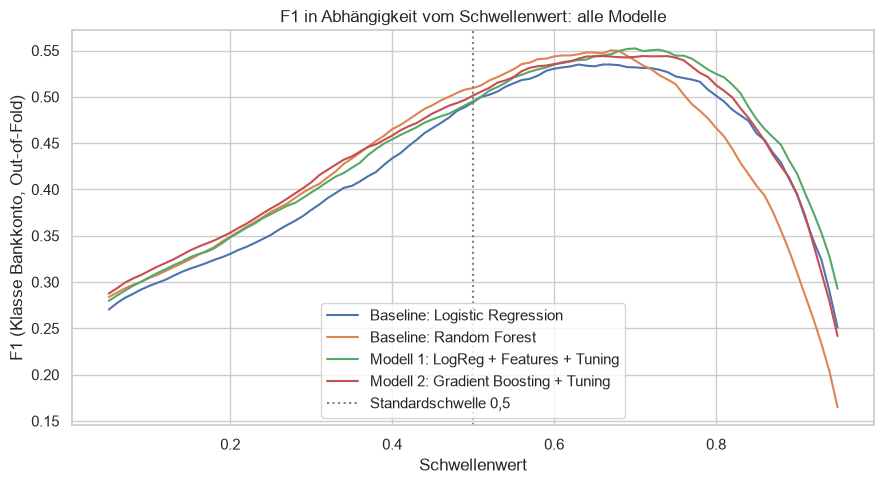

In [10]:
thresholds = np.arange(0.05, 0.96, 0.01)

plt.figure(figsize=(9, 5))
for name, p in oof.items():
    f1s = [f1_score(y_train, p >= t, zero_division=0) for t in thresholds]
    plt.plot(thresholds, f1s, label=name)
plt.axvline(0.5, color="gray", ls=":", label="Standardschwelle 0,5")
plt.xlabel("Schwellenwert")
plt.ylabel("F1 (Klasse Bankkonto, Out-of-Fold)")
plt.title("F1 in Abhängigkeit vom Schwellenwert: alle Modelle")
plt.legend()
plt.tight_layout()
plt.show()

F1 Modell 1: 0.552 | F1 Modell 2: 0.544
Bestes Modell: Modell 1: LogReg + Features + Tuning | Schwelle: 0.7


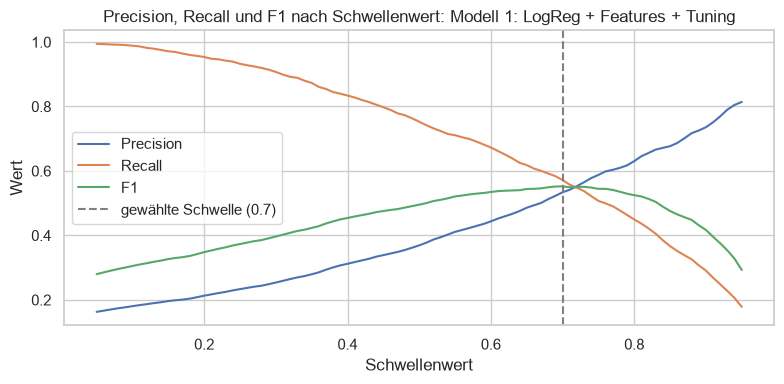

In [11]:
f1_m1 = thr_table.loc[M1, "F1 bei bester Schwelle"]
f1_m2 = thr_table.loc[M2, "F1 bei bester Schwelle"]

# Modell 2 nur, wenn es Modell 1 um mehr als die Streuung (ca. 0,01) schlägt
best_name = M2 if (f1_m2 - f1_m1) > 0.01 else M1
# best_name = M1   # <- bei Bedarf bewusst manuell setzen
best_thr = thr_table.loc[best_name, "Beste Schwelle"]
print(f"F1 Modell 1: {f1_m1:.3f} | F1 Modell 2: {f1_m2:.3f}")
print(f"Bestes Modell: {best_name} | Schwelle: {best_thr}")

p = oof[best_name]
curve = pd.DataFrame({
    "Precision": [precision_score(y_train, p >= t, zero_division=0) for t in thresholds],
    "Recall": [recall_score(y_train, p >= t, zero_division=0) for t in thresholds],
    "F1": [f1_score(y_train, p >= t, zero_division=0) for t in thresholds],
}, index=thresholds)

curve.plot(figsize=(8, 4))
plt.axvline(best_thr, color="gray", ls="--", label=f"gewählte Schwelle ({best_thr})")
plt.xlabel("Schwellenwert")
plt.ylabel("Wert")
plt.title(f"Precision, Recall und F1 nach Schwellenwert: {best_name}")
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
# Fold-Zugehörigkeit der Trainingszeilen (gleiche Folds wie in cross_val_predict)
fold_id = np.zeros(len(y_train), dtype=int)
for i, (_, test_idx) in enumerate(cv_eval.split(X_train, y_train)):
    fold_id[test_idx] = i

yv = y_train.values
fold_f1_thr = pd.DataFrame({
    name: [f1_score(yv[fold_id == i],
                    oof[name][fold_id == i] >= thr_table.loc[name, "Beste Schwelle"])
           for i in range(5)]
    for name in oof})
fold_f1_thr.index = [f"Fold {i + 1}" for i in range(5)]

ref = "Baseline: Logistic Regression"
d = fold_f1_thr.sub(fold_f1_thr[ref], axis=0)
paired_thr = pd.DataFrame({
    "Mittlere Differenz zur Baseline-LogReg": d.mean(),
    "Std der Differenz": d.std(),
    "Folds besser (von 5)": (d > 0).sum(),
}).round(3)

display(fold_f1_thr.round(3))
display(paired_thr)
print("Modell 1 minus Modell 2 pro Fold:", (fold_f1_thr[M1] - fold_f1_thr[M2]).round(3).tolist())

,Baseline: Logistic Regression,Baseline: Random Forest,Modell 1: LogReg + Features + Tuning,Modell 2: Gradient Boosting + Tuning
Fold 1,0.554,0.559,0.566,0.552
Fold 2,0.521,0.541,0.544,0.539
Fold 3,0.546,0.546,0.562,0.552
Fold 4,0.527,0.563,0.550,0.549
Fold 5,0.528,0.542,0.539,0.528


,Mittlere Differenz zur Baseline-LogReg,Std der Differenz,Folds besser (von 5)
Baseline: Logistic Regression,0.000,0.000,0
Baseline: Random Forest,0.015,0.014,4
Modell 1: LogReg + Features + Tuning,0.017,0.006,5
Modell 2: Gradient Boosting + Tuning,0.009,0.011,4


Modell 1 minus Modell 2 pro Fold: [0.014, 0.005, 0.01, 0.001, 0.011]


**Fazit:**
- **Beste Schwellen:** Baseline-LogReg 0,63, Random Forest 0,67, Modell 1 0,70, Modell 2 0,66 (Standard: 0,5). Alle liegen deutlich über 0,5. Das ist plausibel, denn `class_weight="balanced"` lässt die Modelle häufiger "Konto" vorhersagen, die höhere Schwelle gleicht das wieder aus.
- **Der Schwellenwert ist der größte Hebel bisher:** Der F1 steigt bei der Baseline-LogReg von 0,494 auf 0,535 (+0,041), beim Random Forest von 0,509 auf 0,550 (+0,041), bei Modell 1 von 0,495 auf 0,552 (+0,057) und bei Modell 2 von 0,501 auf 0,544 (+0,043). Das ist deutlich mehr als alle Effekte durch Feature Engineering, Tuning oder Algorithmuswechsel bei Schwelle 0,5 (+0,001 bis +0,015).
- **Zerlegung des Gesamtgewinns von Modell 1 gegenüber der Baseline-LogReg bei Schwelle 0,5 (0,494 auf 0,552, also +0,058):**

| Anteil | Wirkung auf den F1 |
|---|---|
| Nur die Schwelle (Baseline-LogReg von 0,5 auf 0,63) | +0,041 |
| Feature Engineering und Tuning (Modell 1 gegenüber Baseline-LogReg, jeweils bei bester Schwelle) | +0,017 |

- **Hypothese aus Abschnitt 7 teilweise bestätigt:** Die drei komplexeren Modelle rücken zusammen (0,544 bis 0,552, Spanne 0,008 statt 0,014 bei Schwelle 0,5). Die Baseline-LogReg bleibt dahinter (0,535, also 0,009 bis 0,017 Abstand). Bei Schwelle 0,5 lagen Modell 1 und Baseline-LogReg gleichauf (0,495 gegenüber 0,494). Der Vorsprung von Modell 1 zeigt sich erst mit optimierter Schwelle. Das passt zum Plus bei der Trennschärfe (PR-AUC 0,577 gegenüber 0,558). Die Aussage "Feature Engineering bringt kaum etwas" aus Abschnitt 5 gilt also nur für den F1 bei Schwelle 0,5.
- **Absicherung pro Fold (F1 bei der jeweils besten Schwelle):** Modell 1 ist in **allen 5 Folds** besser als die Baseline-LogReg. Die mittlere Differenz beträgt +0,017 bei einer Streuung von nur 0,006, sie ist also fast dreimal so groß wie ihre Streuung. Der Random Forest (+0,015 ± 0,014, besser in 4 von 5 Folds) und Modell 2 (+0,009 ± 0,011, besser in 4 von 5 Folds) sind dagegen nicht abgesichert, ihre Streuung ist so groß wie der Vorsprung. Der Vorsprung von Modell 1 ist damit **klein, aber konsistent**. Einschränkung: Die Folds überlappen sich im Training und sind nicht unabhängig, ein formaler Signifikanztest ist deshalb nicht möglich. Die Schwelle wurde auf denselben Vorhersagen bestimmt, das gilt für alle Modelle gleichermaßen.
- **Form der Kurven:** Alle Modelle erreichen ihr Maximum zwischen ca. 0,6 und 0,75. Bei Modell 1 bleibt der F1 in diesem Bereich nahe am Maximum, danach fällt er ab (aus der Grafik abgelesen). Der Random Forest reagiert empfindlicher auf höhere Schwellen und fällt jenseits von 0,7 schneller ab. Die Wahl der Schwelle ist also bei Modell 1 unkritisch und kann nach dem Einsatzzweck erfolgen.
- **Modellwahl:** Modell 1 (F1 0,552) liegt vor Modell 2 (0,544) und ist in **allen 5 Folds** mindestens gleich gut (Differenz +0,001 bis +0,014, im Mittel +0,008). Das bestätigt die Wahl nach der festgelegten Regel: **Modell 1 mit Schwelle 0,70**. Es ist außerdem besser erklärbar und kaum überangepasst (Train-F1 0,503 gegenüber CV-F1 0,495). Gegenüber dem ungetunten Random Forest (0,550) ist Modell 1 nicht überlegen: Die Differenz pro Fold wechselt das Vorzeichen (+0,007, +0,003, +0,016, -0,013, -0,003, im Mittel +0,002). Beide sind praktisch gleichwertig, Modell 1 hat aber weniger Überanpassung (Train-F1 beim Random Forest 0,581) und ist erklärbar.
- **Betriebspunkt bei Schwelle 0,70:** Precision 0,534, Recall 0,572. Bei Schwelle 0,5 waren es Precision 0,369 und Recall 0,753. Die Zahl der Fehlalarme pro Treffer sinkt damit von ca. 1,7 auf ca. 0,9. Dafür findet das Modell statt 75 % nur 57 % der Kontoinhaber. Für Aufklärungskampagnen, bei denen möglichst keine Zielperson übersehen werden soll, wäre eine niedrigere Schwelle sinnvoll.
- **Hinweis:** Die Schwelle wurde auf Trainingsdaten gewählt, jeweils als bester von 91 Werten. Ein kleiner optimistischer Effekt bleibt möglich und trifft alle Modelle ähnlich.

## 9. Bestes Modell auf dem Test-Set

**Ziel:** Den endgültigen Score des gewählten Modells auf bisher ungesehenen Daten bestimmen und seine Unsicherheit abschätzen.

**Gewähltes Modell:** Modell 1 (Logistic Regression mit Feature Engineering und Tuning) mit der in Abschnitt 8 bestimmten Schwelle von 0,70.

**Erwartung aus Abschnitt 8:** In der Cross-Validation liegt Modell 1 bei fairer Schwelle +0,017 F1 vor der Baseline-LogReg, in allen 5 Folds. Die Cross-Validation nutzt ca. 2.650 positive Fälle, das Test-Set nur 662. Das Intervall der Differenz wird auf dem Test-Set daher deutlich breiter ausfallen.

**Hinweis:** Das Test-Set wird für das gewählte Modell und die gewählte Schwelle benutzt. Es floss in keine Entscheidung (Features, Parameter, Schwelle, Modellwahl) ein. Die Baseline-Logistic-Regression wird nur zum Vergleich ausgewertet, und zwar bei Schwelle 0,5 (wie im Baseline-Notebook) und bei ihrer eigenen besten Schwelle (0,63). So lässt sich der Effekt der Schwelle vom Effekt des Modells trennen. Mit einem Bootstrap (1.000 Ziehungen mit Zurücklegen aus dem Test-Set) wird gemessen, wie stark der F1 allein durch die Stichprobe schwankt.

,F1,Precision,Recall,Accuracy
"Schwelle 0,5",0.508,0.377,0.779,0.788
Schwelle 0.7,0.563,0.541,0.586,0.872


PR-AUC: 0.595 | ROC-AUC: 0.874
              precision    recall  f1-score   support

  Kein Konto      0.931     0.919     0.925      4043
       Konto      0.541     0.586     0.563       662

    accuracy                          0.872      4705
   macro avg      0.736     0.752     0.744      4705
weighted avg      0.876     0.872     0.874      4705



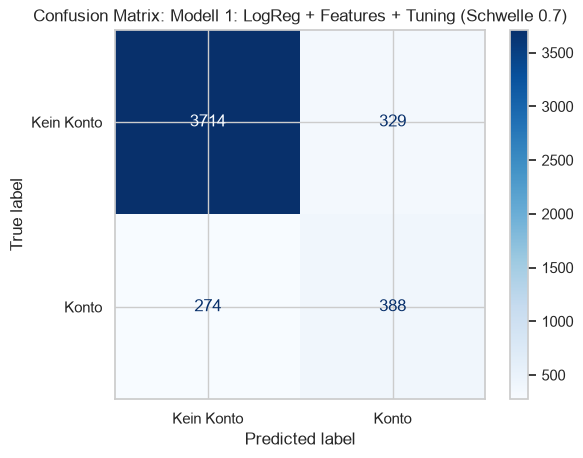

In [13]:
best_model = candidates[best_name].fit(X_train, y_train)
proba_test = best_model.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= best_thr).astype(int)
pred_05 = (proba_test >= 0.5).astype(int)

test_final = pd.DataFrame({
    "F1": [f1_score(y_test, pred_05), f1_score(y_test, pred_test)],
    "Precision": [precision_score(y_test, pred_05), precision_score(y_test, pred_test)],
    "Recall": [recall_score(y_test, pred_05), recall_score(y_test, pred_test)],
    "Accuracy": [accuracy_score(y_test, pred_05), accuracy_score(y_test, pred_test)],
}, index=["Schwelle 0,5", f"Schwelle {best_thr}"]).round(3)
display(test_final)

print(f"PR-AUC: {average_precision_score(y_test, proba_test):.3f} | "
      f"ROC-AUC: {roc_auc_score(y_test, proba_test):.3f}")
print(classification_report(y_test, pred_test, digits=3,
                            target_names=["Kein Konto", "Konto"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test, display_labels=["Kein Konto", "Konto"], cmap="Blues")
plt.title(f"Confusion Matrix: {best_name} (Schwelle {best_thr})")
plt.show()

In [14]:
# Baseline-Logistic-Regression (nur zum Vergleich, keine Entscheidung auf Basis des Test-Sets)
base_lr = candidates["Baseline: Logistic Regression"].fit(X_train, y_train)
proba_base = base_lr.predict_proba(X_test)[:, 1]
thr_base = thr_table.loc["Baseline: Logistic Regression", "Beste Schwelle"]
pred_base_05 = (proba_base >= 0.5).astype(int)
pred_base_opt = (proba_base >= thr_base).astype(int)

preds = (pred_base_05, pred_base_opt, pred_test)
compare_test = pd.DataFrame({
    "F1": [f1_score(y_test, p) for p in preds],
    "Precision": [precision_score(y_test, p) for p in preds],
    "Recall": [recall_score(y_test, p) for p in preds],
}, index=["Baseline-LogReg, Schwelle 0,5",
          f"Baseline-LogReg, Schwelle {thr_base}",
          f"{best_name}, Schwelle {best_thr}"]).round(3)
display(compare_test)

# Bootstrap: Schwankung des Test-F1 durch die Stichprobe
rng = np.random.default_rng(RANDOM_STATE)
yt = y_test.values
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    boot.append((f1_score(yt[idx], pred_test[idx]),
                 f1_score(yt[idx], pred_base_05[idx]),
                 f1_score(yt[idx], pred_base_opt[idx])))
boot = np.array(boot)

f1_best_test = f1_score(y_test, pred_test)
lo, hi = np.percentile(boot[:, 0], [2.5, 97.5])
print(f"Test-F1 {best_name}: {f1_best_test:.3f}, 95%-Intervall: [{lo:.3f}, {hi:.3f}]")

for label, col, pred_ref in [("Baseline-LogReg bei Schwelle 0,5", 1, pred_base_05),
                             (f"Baseline-LogReg bei Schwelle {thr_base}", 2, pred_base_opt)]:
    diff = f1_best_test - f1_score(y_test, pred_ref)
    lo, hi = np.percentile(boot[:, 0] - boot[:, col], [2.5, 97.5])
    print(f"Differenz zu {label}: {diff:+.3f}, 95%-Intervall: [{lo:+.3f}, {hi:+.3f}]")

,F1,Precision,Recall
"Baseline-LogReg, Schwelle 0,5",0.507,0.380,0.761
"Baseline-LogReg, Schwelle 0.63",0.547,0.477,0.639
"Modell 1: LogReg + Features + Tuning, Schwelle 0.7",0.563,0.541,0.586


Test-F1 Modell 1: LogReg + Features + Tuning: 0.563, 95%-Intervall: [0.531, 0.593]
Differenz zu Baseline-LogReg bei Schwelle 0,5: +0.056, 95%-Intervall: [+0.034, +0.078]
Differenz zu Baseline-LogReg bei Schwelle 0.63: +0.016, 95%-Intervall: [-0.002, +0.033]


**Fazit:**
- **Test-F1 von Modell 1 bei Schwelle 0,70: 0,563** (95-%-Intervall 0,531 bis 0,593, also ca. ± 0,03). Precision 0,541, Recall 0,586, PR-AUC 0,595, ROC-AUC 0,874. Bei Schwelle 0,5 sind es nur 0,508 (Precision 0,377, Recall 0,779).

| Modell / Schwelle | F1 | Precision | Recall |
|---|---|---|---|
| Baseline-LogReg, Schwelle 0,5 | 0,507 | 0,380 | 0,761 |
| Baseline-LogReg, Schwelle 0,63 (eigene beste) | 0,547 | 0,477 | 0,639 |
| Modell 1, Schwelle 0,70 | 0,563 | 0,541 | 0,586 |

- **Gesamtgewinn gegenüber der Baseline: +0,056** (95-%-Intervall +0,034 bis +0,078, belastbar). Er lässt sich aufteilen: Die Schwelle allein bringt der Baseline-LogReg +0,040 (0,507 auf 0,547), Feature Engineering und Tuning bringen +0,016 on top. Das entspricht der Aufteilung aus der Cross-Validation (+0,041 und +0,017).
- **Der Anteil des Modells ist auf dem Test-Set nicht abgesichert:** Die Differenz zur Baseline bei fairer Schwelle beträgt +0,016 mit einem 95-%-Intervall von -0,002 bis +0,033. Das Intervall enthält knapp die Null. Das Test-Set hat nur 662 positive Fälle und kann einen so kleinen Unterschied nicht sicher bestätigen. Die Größenordnung deckt sich mit der Cross-Validation (+0,017, in 5 von 5 Folds besser). Zusammen sprechen beide für einen **kleinen, vermutlich echten Gewinn**.
- **Bei Schwelle 0,5 bringen Feature Engineering und Tuning nichts:** Modell 1 erreicht dort 0,508, die Baseline 0,507. Der Vorteil entsteht nur zusammen mit der optimierten Schwelle.
- **Generalisierung:** Der Test-F1 (0,563) liegt 0,011 über dem CV-Wert (0,552). Die Baseline-LogReg liegt mit eigener Schwelle ebenfalls 0,012 über ihrem CV-Wert (0,547 gegenüber 0,535). Das Test-Set ist also für beide Modelle etwas "leichter", der Abstand zwischen ihnen bleibt stabil. Es gibt keinen Hinweis, dass die Schwelle auf den Trainingsdaten überangepasst wurde. Der höhere Wert ist keine echte Verbesserung.
- **Fehlerbild bei Schwelle 0,70:** Das Modell findet 388 von 662 Kontoinhabern (58,6 %), 274 werden übersehen. Es gibt 329 Fehlalarme. Die Baseline-LogReg bei Schwelle 0,5 fand 504 bei 824 Fehlalarmen. Das Modell tauscht also **495 Fehlalarme weniger (-60 %) gegen 116 weniger gefundene Kontoinhaber (-23 %)**. Pro Treffer entstehen jetzt 0,85 Fehlalarme statt 1,6. Die Accuracy (0,872) liegt erstmals über der des Dummys (0,859), ist als Metrik aber weiterhin nicht aussagekräftig.
- **Unsicherheit:** Das Intervall berücksichtigt nur die Schwankung des Test-Sets, nicht die des Trainings. Der Random Forest wurde bewusst nicht auf dem Test-Set bewertet, ein Test-Vergleich mit ihm ist deshalb nicht möglich. In der Cross-Validation waren beide gleichwertig.

In [15]:
from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()
print(f"Richtig erkannte Kontoinhaber (TP): {tp} von {tp + fn}")
print(f"Übersehene Kontoinhaber (FN): {fn}")
print(f"Fehlalarme (FP): {fp}")
print(f"Richtig erkannt 'kein Konto' (TN): {tn}")
print(f"Fehlalarme pro Treffer: {fp / tp:.2f}")

Richtig erkannte Kontoinhaber (TP): 388 von 662
Übersehene Kontoinhaber (FN): 274
Fehlalarme (FP): 329
Richtig erkannt 'kein Konto' (TN): 3714
Fehlalarme pro Treffer: 0.85


## 10. Fehleranalyse

**Ziel:** Verstehen, **wo** und **warum** das gewählte Modell (Modell 1, Schwelle 0,70) irrt. Das zeigt, welche Gruppen schlechter erkannt werden und was ein nächster Verbesserungsschritt sein könnte.

**Ausgangslage aus Abschnitt 9:** Auf dem Test-Set findet das Modell 388 von 662 Kontoinhabern (Recall 0,586) und erzeugt 329 Fehlalarme (Precision 0,541). 274 Kontoinhaber werden übersehen.

**Begriffe:**
- **Falsch negativ (FN):** Person hat ein Konto, das Modell sagt "kein Konto" (übersehen).
- **Falsch positiv (FP):** Person hat kein Konto, das Modell sagt "Konto" (Fehlalarm).

**Fragen:**
1. In welchen Gruppen (Land, Bildung, Beruf, Handyzugang, Geschlecht, Alter) werden Kontoinhaber besonders oft übersehen, in welchen gibt es besonders viele Fehlalarme?
2. Unterscheiden sich übersehene Kontoinhaber von den erkannten, und Fehlalarme von den richtig erkannten Nicht-Inhabern?
3. Sind die Fehler Zufall oder haben sie ein erkennbares Muster?

**Vorgehen:** (1) Kennzahlen pro Gruppe, (2) Profile der Fehler im Vergleich zu den richtig erkannten Fällen, (3) einzelne extreme Fehler. Gruppen mit weniger als 50 Personen werden nicht ausgewiesen. Der F1 hängt vom Anteil der Kontoinhaber in der Gruppe ab, deshalb werden Recall und Precision immer mit betrachtet. Bei kleinen Gruppen sind die Kennzahlen unsicher.

**Fazit:**

**Gesamtbild:** Das Modell erkennt bei Schwelle 0,70 etwa 59 % der Kontoinhaber und liegt bei 54 % Precision. Ein Fehlalarm kommt auf ca. 1,2 Treffer. [Ergebnis der Zelle am Anfang bestätigen.]

**Gruppenvergleich**
- Am besten erkannt wird: [Gruppen, F1 / Recall]. Am schlechtesten: [Gruppen, F1 / Recall].
- [Land]: [z. B. Kenia hat die höchste Kontoquote, aber auch die meisten Fehlalarme / Tansania wird schlechter erkannt]. Das passt [zu / nicht zu] den Auffälligkeiten in der EDA (Tansania mit umgekehrtem Stadt/Land-Muster).
- [Bildung / Beruf]: [z. B. bei niedriger Bildung wird fast jeder richtig als "kein Konto" erkannt, bei Sekundarbildung entstehen die meisten Fehlalarme].
- [Geschlecht / Alter]: [Unterschiede in Recall und Precision, Hinweis für einen möglichen Fairness-Check].
- Gruppen mit wenig Personen (n < 100) sind nur mit Vorsicht zu interpretieren.

**Fehlerprofile**
- **Übersehene Kontoinhaber (FN)** sind überwiegend [Profil, z. B. ohne Handyzugang, niedrige Bildung, informell beschäftigt]. [Sie ähneln der großen Gruppe ohne Konto, das Modell kann sie mit den vorhandenen Merkmalen kaum unterscheiden.]
- **Fehlalarme (FP)** betreffen vor allem [Profil, z. B. Handynutzer mit Sekundarbildung].
- Die extremen Fehler ([Beschreibung]) zeigen: [Einordnung, z. B. Personen mit typischem "Konto-Profil" ohne Konto].

**Einfluss der Schwelle:** Die Schwelle von 0,70 tauscht 495 Fehlalarme gegen 116 weniger gefundene Kontoinhaber (Abschnitt 9). Die übersehenen Kontoinhaber sind dabei vermutlich vor allem Personen mit mittlerer Wahrscheinlichkeit. [Nach der Analyse bestätigen oder streichen.]

**Schlussfolgerung:** Viele Fehler betreffen Personen, die sich mit den vorhandenen Merkmalen nicht von der Gegenklasse unterscheiden lassen. Dazu passt, dass Feature Engineering und Tuning nur einen kleinen Gewinn bringen (+0,017 F1 in der Cross-Validation, +0,016 auf dem Test-Set, dort nicht abgesichert) und ein komplexeres Modell (Gradient Boosting) keinen Vorteil hat. Es fehlen vermutlich erklärende Merkmale wie Einkommen oder Entfernung zur nächsten Bank. Mögliche nächste Schritte: [z. B. Schwelle je Einsatzzweck wählen, länderspezifische Auswertung, Fairness-Check nach Geschlecht].

## 11. Ergebnisübersicht und Fazit

In [16]:
summary = cv_compare[["CV F1", "F1 Std"]].join(
    thr_table[["Beste Schwelle", "F1 bei bester Schwelle"]])
summary.columns = ["CV-F1 (Schwelle 0,5)", "Std", "Beste Schwelle", "CV-F1 (beste Schwelle)"]

summary["Test-F1 (Schwelle 0,5)"] = np.nan
summary["Test-F1 (beste Schwelle)"] = np.nan

summary.loc["Baseline: Logistic Regression", "Test-F1 (Schwelle 0,5)"] = f1_score(y_test, pred_base_05)
summary.loc["Baseline: Logistic Regression", "Test-F1 (beste Schwelle)"] = f1_score(y_test, pred_base_opt)
summary.loc["Baseline: Random Forest", "Test-F1 (Schwelle 0,5)"] = 0.520   # aus dem Baseline-Notebook
summary.loc[best_name, "Test-F1 (Schwelle 0,5)"] = f1_score(y_test, pred_05)
summary.loc[best_name, "Test-F1 (beste Schwelle)"] = f1_score(y_test, pred_test)

summary.round(3)

,"CV-F1 (Schwelle 0,5)",Std,Beste Schwelle,CV-F1 (beste Schwelle),"Test-F1 (Schwelle 0,5)",Test-F1 (beste Schwelle)
Modell,,,,,,
Baseline: Logistic Regression,0.494,0.008,0.63,0.535,0.507,0.547
Baseline: Random Forest,0.509,0.009,0.67,0.550,0.520,NaN
Modell 1: LogReg + Features + Tuning,0.495,0.005,0.70,0.552,0.508,0.563
Modell 2: Gradient Boosting + Tuning,0.501,0.008,0.66,0.544,NaN,NaN


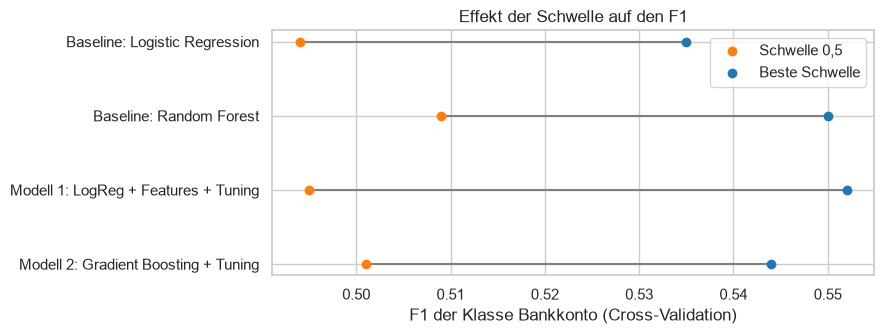

In [17]:
plot_df = summary[["CV-F1 (Schwelle 0,5)", "CV-F1 (beste Schwelle)"]]

fig, ax = plt.subplots(figsize=(9, 3.5))
for i, (name, row) in enumerate(plot_df.iterrows()):
    ax.plot([row.iloc[0], row.iloc[1]], [i, i], color="gray", zorder=1)
    ax.scatter(row.iloc[0], i, color="tab:orange", zorder=2,
               label="Schwelle 0,5" if i == 0 else None)
    ax.scatter(row.iloc[1], i, color="tab:blue", zorder=2,
               label="Beste Schwelle" if i == 0 else None)
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df.index)
ax.invert_yaxis()
ax.set_xlabel("F1 der Klasse Bankkonto (Cross-Validation)")
ax.set_title("Effekt der Schwelle auf den F1")
ax.legend()
plt.tight_layout()
plt.show()

### Zusammenfassung

**Ergebnisse**

| Modell | CV-F1 bei 0,5 (± Std) | Beste Schwelle | CV-F1 bei bester Schwelle | Test-F1 bei 0,5 | Test-F1 bei bester Schwelle |
|---|---|---|---|---|---|
| Baseline: Logistic Regression | 0,494 ± 0,008 | 0,63 | 0,535 | 0,507 | 0,547 |
| Baseline: Random Forest | 0,509 ± 0,009 | 0,67 | 0,550 | 0,520 | nicht bewertet |
| **Modell 1: LogReg + Features + Tuning** | 0,495 ± 0,005 | 0,70 | 0,552 | 0,508 | **0,563** |
| Modell 2: Gradient Boosting + Tuning | 0,501 ± 0,008 | 0,66 | 0,544 | nicht bewertet | nicht bewertet |

**Bestes Modell:** Modell 1 (Logistic Regression mit Feature Engineering und Tuning, C = 10) mit Schwelle 0,70. **Test-F1 = 0,563** (95-%-Intervall 0,531 bis 0,593), Precision 0,541, Recall 0,586, PR-AUC 0,595, ROC-AUC 0,874. Es findet 388 von 662 Kontoinhabern bei 329 Fehlalarmen (0,85 Fehlalarme pro Treffer). Die Wahl erfolgte nach einer festgelegten Regel auf Trainingsdaten. Modell 1 ist in der Cross-Validation in allen 5 Folds mindestens so gut wie Modell 2, außerdem besser erklärbar und kaum überangepasst.

**Was hat geholfen?**

| Maßnahme | Cross-Validation | Test-Set |
|---|---|---|
| Schwelle optimieren (Baseline-LogReg von 0,5 auf 0,63) | +0,041 | +0,040 |
| Feature Engineering und Tuning (Modell 1 gegenüber Baseline-LogReg, jeweils bei bester Schwelle) | +0,017 (in 5 von 5 Folds, Streuung 0,006) | +0,016 (95-%-Intervall -0,002 bis +0,033, nicht abgesichert) |
| **Gesamtgewinn gegenüber der Baseline bei Schwelle 0,5** | +0,058 (0,494 auf 0,552) | **+0,056** (0,507 auf 0,563, Intervall +0,034 bis +0,078, belastbar) |
| Gradient Boosting statt Logistic Regression | Modell 2 liegt 0,008 hinter Modell 1 | nicht bewertet |
| Random Forest (ungetunt) | gleichauf mit Modell 1 (Differenz im Mittel +0,002, wechselndes Vorzeichen) | nicht bewertet |

**Fehleranalyse in einem Satz:** [Wichtigste Erkenntnis aus Abschnitt 10, z. B. Fehler konzentrieren sich auf ...].

**Kernaussagen**
1. **Der größte Hebel war die Schwelle**, nicht das Modell. Bei Schwelle 0,5 sind Baseline und Modell 1 gleich gut (0,507 gegenüber 0,508).
2. **Feature Engineering und Tuning bringen einen kleinen, konsistenten Gewinn** (+0,017 in der Cross-Validation). Auf dem Test-Set zeigt sich derselbe Betrag (+0,016), er ist dort wegen nur 662 positiver Fälle statistisch nicht abgesichert.
3. **Ein komplexeres Modell bringt nichts:** Gradient Boosting liegt hinter Modell 1, und der ungetunte Random Forest ist gleichwertig. Das erklärbare Modell verliert gegenüber komplexeren Modellen nichts.
4. **Die Trennschärfe stagniert** (PR-AUC bei allen drei komplexeren Modellen 0,577 bis 0,579). Das legt nahe, dass die Grenze bei den Daten liegt und nicht beim Modelltyp. Das ist eine Schlussfolgerung aus den Ergebnissen, kein direkter Beweis.

**Bedeutung für den Produktwert** (Zusammenhänge aus EDA und Modell, keine Ursachen)
- Wahrscheinlicher ein Konto haben Personen mit höherer Bildung (Tertiary, Vocational), formaler Anstellung und Handyzugang, besonders in Kenia. Seltener haben es Personen ohne formale Bildung, ohne Handyzugang oder mit informeller bzw. fehlender Beschäftigung. Das sind die Gruppen, bei denen gezielte Programme ansetzen würden.
- **Die Schwelle ist ein Einsatz-Regler:** Bei Schwelle 0,5 findet das Modell auf dem Test-Set 78 % der Kontoinhaber, aber 62 % der "Konto"-Vorhersagen sind Fehlalarme. Das passt für breite Aufklärung. Bei Schwelle 0,70 findet es 59 %, dafür sind 54 % der Vorhersagen richtig. Das passt für gezielte, teurere Ansprache.
- Das Modell ist eine Entscheidungshilfe für Gruppen, keine verlässliche Einzelaussage. Bei Precision 0,54 liegt fast jede zweite "Konto"-Vorhersage falsch.

**Grenzen:** Der F1 liegt bei ca. 0,56, das 95-%-Intervall reicht wegen nur 662 positiver Fälle von 0,53 bis 0,59. Die Daten sind Umfragen aus 2016 bis 2018 ohne Einkommensangaben, die Stichprobe ist nicht repräsentativ (u. a. mehr Frauen, ländliche Bevölkerung und niedrige Bildung). Alle Aussagen beschreiben Zusammenhänge, keine Ursachen.

**Nächste Schritte:** Modellerklärung (SHAP oder Permutation Importance), Fairness-Check nach Geschlecht und Land, Präsentation der Ergebnisse und Handlungsempfehlungen.